# Modeling: Predicting Severe Mental Health ED Stays

**Question:** Which hospital characteristics predict the longest ED stays for mental health patients?

**Target:** `severe` = 1 if a hospital's mental health ED length of stay (OP-18c) is in the
top 25% (324+ minutes), otherwise 0. Created in `2. Data Preprocessing and EDA.ipynb`.

**Approach:**
1. Split the data into training (80%) and test (20%) sets
2. Prepare features: fill blanks and scale numeric features; one-hot encode categories
3. Baseline model that always predicts "not severe"
4. Logistic regression, checked with 5-fold cross-validation on the training set
5. Evaluate on the test set (confusion matrix, recall, AUC)
6. Interpret the results with odds ratios
7. Check how well the model works for rural (Critical Access) hospitals

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#load the model-ready data from the preprocessing notebook
model_df = pd.read_csv("../data/Processed/model_ready.csv", dtype={"facility_id": str})

print(model_df.shape)
model_df.head()

(3018, 14)


,facility_id,Facility Name,State,wait_psych,severe,wait_regular,Hospital overall rating,Count of MORT Measures Worse,Count of Safety Measures Worse,Count of READM Measures Worse,er_volume,region,Hospital Type,ownership_group
0,010005,MARSHALL MEDICAL CENTERS,AL,242.0,0,143.0,3.0,1.0,0.0,0.0,very high,South,Acute Care Hospitals,Government
1,010006,NORTH ALABAMA MEDICAL CENTER,AL,218.0,0,147.0,2.0,3.0,0.0,0.0,high,South,Acute Care Hospitals,For-profit
2,010007,MIZELL MEMORIAL HOSPITAL,AL,242.0,0,130.0,1.0,1.0,0.0,2.0,low,South,Acute Care Hospitals,Non-profit
3,010012,DEKALB REGIONAL MEDICAL CENTER,AL,346.0,1,164.0,2.0,0.0,0.0,2.0,medium,South,Acute Care Hospitals,For-profit
4,010016,SHELBY BAPTIST MEDICAL CENTER,AL,96.0,0,182.0,2.0,0.0,1.0,1.0,medium,South,Acute Care Hospitals,Non-profit


## Features and target
The model uses 9 hospital characteristics. ID, name, and state are kept out because they
don't describe the hospital. `wait_psych` is kept out because the target is made from it,
so including it would let the model "see the answer" (data leakage).

In [62]:
#target: 1 = severe, 0 = not severe
y = model_df["severe"]

#numeric and categorical features
num_features = ["wait_regular", "Hospital overall rating",
                "Count of MORT Measures Worse", "Count of Safety Measures Worse",
                "Count of READM Measures Worse"]
cat_features = ["er_volume", "region", "Hospital Type", "ownership_group"]

#features only (no IDs, names, State, or wait_psych)
X = model_df[num_features + cat_features]

print(X.shape)
print(y.value_counts())

(3018, 9)
severe
0    2259
1     759
Name: count, dtype: int64


## Train/test split
The data is split into 80% training and 20% test. The model learns only from the
training set, and the test set is used once at the end to see how it performs on
hospitals it has never seen.

`stratify=y` keeps the same share of severe hospitals (about 25%) in both sets.
`random_state=42` makes the split the same every time the notebook is run.

In [63]:
from sklearn.model_selection import train_test_split

#80% train, 20% test, same share of severe hospitals in both
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

#check sizes and the share of severe in each
print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(2414, 9) (604, 9)
0.251 0.252


## Preparing the features
Logistic regression needs complete, numeric inputs, so the features are prepared in a pipeline:

**Numeric features** (`wait_regular`, star rating, the three "Worse" counts):
- Blanks are filled with the **median** of the training set. The median isn't pulled by outliers.
- Values are **scaled** (mean 0, standard deviation 1) so features measured in different units
  (minutes vs. counts) can be compared. Odds ratios are then read "per 1 standard deviation."

**Categorical features** (ER volume, region, hospital type, ownership):
- **One-hot encoded:** each category becomes its own 0/1 column.
- One category per feature is left out as the **reference group**, and the others are
  compared to it: low ER volume, Midwest, Acute Care, and Non-profit.

Because this is done in a pipeline, the medians and scaling are learned from the training
set only and then applied to the test set, so no test information leaks into training.

In [64]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

#numeric: fill blanks with the median, then scale
num_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

#categorical: one-hot encode, leaving out one reference group per feature
#(the order matches cat_features: er_volume, region, Hospital Type, ownership_group)
cat_pipe = OneHotEncoder(drop=["low", "Midwest", "Acute Care Hospitals", "Non-profit"])

#apply each to the right columns
preprocess = ColumnTransformer([
    ("num", num_pipe, num_features),
    ("cat", cat_pipe, cat_features)
])

## Baseline: dummy model
The baseline always predicts the most common class, "not severe." It ignores every
feature, so it shows what performance looks like with no real learning.

- **Accuracy** will be about 75%, just because 75% of hospitals are not severe.
- **Recall** (the share of severe hospitals the model finds) will be 0, because it never predicts severe.
- **AUC** will be 0.5, the same as guessing at random.

Logistic regression needs to clearly beat these numbers to be useful.

Scores come from **5-fold cross-validation on the training set**: the training data is split
into 5 parts, and the model is trained on 4 and scored on the 5th, five times. Averaging
the 5 scores gives a more stable estimate than a single split. The test set is not used yet.

In [65]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

#same 5 folds for every model (stratified keeps ~25% severe in each fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#baseline: always predicts "not severe"
dummy = Pipeline([
    ("prep", preprocess),
    ("model", DummyClassifier(strategy="most_frequent"))
])

#5-fold cross-validation on the training set
dummy_cv = cross_validate(dummy, X_train, y_train, cv=cv,
                          scoring=["accuracy", "recall", "roc_auc"])

#average score across the 5 folds
print("Accuracy:", dummy_cv["test_accuracy"].mean().round(3))
print("Recall:  ", dummy_cv["test_recall"].mean().round(3))
print("AUC:     ", dummy_cv["test_roc_auc"].mean().round(3))

Accuracy: 0.749
Recall:   0.0
AUC:      0.5


The baseline is 74.9% accurate but has a recall of 0: it never identifies a single severe
hospital. Its AUC of 0.5 is the same as random guessing. This confirms that accuracy alone
is misleading here, so logistic regression is judged mainly on recall and AUC.

## Logistic regression
Logistic regression estimates the probability that a hospital is severe from its
characteristics. It was chosen because it is interpretable: each feature gets a
coefficient that can be turned into an odds ratio, showing which characteristics are
linked to severe ED stays and in which direction.

`class_weight="balanced"` gives the severe hospitals more weight during training.
Without it, the model would lean toward predicting "not severe" (the majority class)
and miss many severe hospitals. Default settings are used otherwise, since the goal
is interpretation rather than squeezing out extra accuracy.

It is scored with the same 5 folds as the baseline, plus **precision** (of the hospitals
flagged as severe, how many really are).

In [66]:
from sklearn.linear_model import LogisticRegression

#logistic regression with the same preprocessing
logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000))
])

#5-fold cross-validation on the training set (same folds as the baseline)
logreg_cv = cross_validate(logreg, X_train, y_train, cv=cv,
                           scoring=["accuracy", "recall", "precision", "roc_auc"])

#average across the 5 folds, with the spread (std) to show how stable it is
for m in ["accuracy", "recall", "precision", "roc_auc"]:
    scores = logreg_cv["test_" + m]
    print(f"{m:10s} mean = {scores.mean():.3f}   std = {scores.std():.3f}")

accuracy   mean = 0.715   std = 0.021
recall     mean = 0.685   std = 0.045
precision  mean = 0.456   std = 0.026
roc_auc    mean = 0.781   std = 0.022


Compared with the baseline, logistic regression finds about 69% of severe hospitals
(recall 0.685 vs. 0) and has an AUC of 0.78 (vs. 0.5 for random guessing). Of the
hospitals it flags as severe, about 46% truly are (precision 0.456), nearly twice the
25% expected from random guessing.

Accuracy is slightly lower than the baseline (0.715 vs. 0.749). This is expected:
balancing the classes makes the model look for severe hospitals, so it catches many more
of them while also flagging some that aren't severe. For a screening tool, finding most
severe hospitals matters more than overall accuracy.

The small standard deviations (0.02–0.045) show the results are stable across the 5 folds.

## Final evaluation on the test set
The model is now trained on the full training set (2,414 hospitals) and evaluated once
on the 604 test hospitals it has never seen. This gives an honest estimate of how it
would perform on new hospitals.

- **Confusion matrix:** counts of correct and incorrect predictions for each class
- **Recall, precision, AUC:** the same metrics used in cross-validation

In [67]:
from sklearn.metrics import (recall_score, precision_score, accuracy_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)

#train on the full training set
logreg.fit(X_train, y_train)

#predictions on the test set
y_pred = logreg.predict(X_test)                 #0 or 1
y_prob = logreg.predict_proba(X_test)[:, 1]     #probability of being severe

#test set scores
print("Accuracy: ", round(accuracy_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("AUC:      ", round(roc_auc_score(y_test, y_prob), 3))

Accuracy:  0.724
Recall:    0.684
Precision: 0.466
AUC:       0.796


On the 604 test hospitals, the model finds 68% of severe hospitals (recall 0.684), with an
AUC of 0.80. These results are very close to the cross-validation results (recall 0.685,
AUC 0.78), which shows the model is not overfitting and performs consistently on hospitals
it has not seen before.

## Which hospital characteristics matter? (Odds ratios)
Each coefficient is turned into an **odds ratio** (exp of the coefficient):
- **Above 1:** higher odds of a severe ED stay
- **Below 1:** lower odds
- **Close to 1:** little association

Numeric features were scaled, so their odds ratios are **per 1 standard deviation increase**.
Category odds ratios are **compared to the reference group**: low ER volume, Midwest,
Acute Care, and Non-profit.

These show association, not cause.

In [68]:
#feature names after preprocessing (one-hot columns included)
feature_names = logreg.named_steps["prep"].get_feature_names_out()

#coefficients -> odds ratios
coefs = logreg.named_steps["model"].coef_[0]
odds = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefs,
    "odds_ratio": np.exp(coefs)
}).sort_values("odds_ratio", ascending=False)

odds.round(3)

,feature,coefficient,odds_ratio
0,num__wait_regular,1.141,3.130
9,cat__region_Northeast,0.319,1.375
13,cat__ownership_group_For-profit,0.315,1.370
14,cat__ownership_group_Government,0.093,1.097
10,cat__region_South,0.085,1.088
4,num__Count of READM Measures Worse,0.065,1.067
1,num__Hospital overall rating,-0.015,0.985
3,num__Count of Safety Measures Worse,-0.024,0.976
2,num__Count of MORT Measures Worse,-0.045,0.956
7,cat__er_volume_medium,-0.075,0.928


In [69]:
#how many minutes is 1 standard deviation of regular ED time (training set)?
X_train["wait_regular"].std()

51.14500684746057

### Which odds ratios are statistically significant?
scikit-learn does not report p-values or confidence intervals, so the same features are
refit with statsmodels' `Logit` on the training set. A 95% confidence interval for an
odds ratio that does not include 1 means the association is statistically significant.

Note: this version does not use class weights or scikit-learn's default regularization,
so the odds ratios can differ slightly from the table above. It is used to check which
associations are reliable, not to replace the model.

In [70]:
import statsmodels.api as sm

#use the same preprocessing (fitted on the training set) to prepare the training data
Xt = logreg.named_steps["prep"].transform(X_train)
Xt = pd.DataFrame(Xt, columns=feature_names, index=X_train.index)

#add an intercept and fit the logistic regression
sm_model = sm.Logit(y_train, sm.add_constant(Xt)).fit(disp=0)

#odds ratios with 95% confidence intervals and p-values
ci = np.exp(sm_model.conf_int())
sig = pd.DataFrame({
    "odds_ratio": np.exp(sm_model.params),
    "ci_lower": ci[0],
    "ci_upper": ci[1],
    "p_value": sm_model.pvalues
}).drop("const").sort_values("odds_ratio", ascending=False)

sig.round(3)

,odds_ratio,ci_lower,ci_upper,p_value
num__wait_regular,3.058,2.632,3.552,0.000
cat__ownership_group_For-profit,1.322,0.960,1.820,0.088
cat__region_Northeast,1.298,0.939,1.793,0.114
cat__region_South,1.112,0.842,1.469,0.453
num__Count of READM Measures Worse,1.057,0.941,1.188,0.350
cat__ownership_group_Government,1.026,0.758,1.387,0.869
num__Hospital overall rating,0.991,0.885,1.111,0.881
num__Count of Safety Measures Worse,0.966,0.874,1.068,0.496
num__Count of MORT Measures Worse,0.963,0.872,1.065,0.467
cat__er_volume_medium,0.920,0.649,1.303,0.638


Only one characteristic is clearly significant: **regular ED time** (OR = 3.06, 95% CI
2.63–3.55, p < 0.001). Each additional standard deviation (about 51 minutes) of regular
ED time is linked to about 3 times the odds of a severe mental health ED stay.

Hospitals in the West had lower odds than the Midwest (OR = 0.73, p = 0.048), but this is
borderline and could be due to chance given the number of features tested. For-profit
ownership (OR = 1.32, p = 0.088) and high ER volume (OR = 0.70, p = 0.086) show weak
evidence only. All other characteristics, including hospital type, star rating, and the
quality "Worse" counts, are not significant.

**Interpretation:** once overall ED flow is known, hospital characteristics add little.
ER volume looked important in the EDA, but it is not significant after accounting for
regular ED time, which suggests busy EDs have long mental health stays mainly because
they are more crowded. For hospitals, this points to overall ED flow as the main place
to look, not hospital type or overall rating.

## Model without regular ED time
Regular ED time dominates the model. To see what the other hospital characteristics can
predict on their own, the same logistic regression is refit **without** `wait_regular`.

- If performance drops a lot, ED flow is doing most of the work.
- If other features become significant, they matter when ED flow is unknown, possibly
  because they are related to how crowded the ED is.

In [71]:
#numeric features without wait_regular
num_no_wait = ["Hospital overall rating", "Count of MORT Measures Worse",
               "Count of Safety Measures Worse", "Count of READM Measures Worse"]

#same preprocessing, minus wait_regular
preprocess_no_wait = ColumnTransformer([
    ("num", num_pipe, num_no_wait),
    ("cat", cat_pipe, cat_features)
])

logreg_no_wait = Pipeline([
    ("prep", preprocess_no_wait),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000))
])

#same 5-fold cross-validation on the training set
no_wait_cv = cross_validate(logreg_no_wait, X_train, y_train, cv=cv,
                            scoring=["accuracy", "recall", "precision", "roc_auc"])

for m in ["accuracy", "recall", "precision", "roc_auc"]:
    scores = no_wait_cv["test_" + m]
    print(f"{m:10s} mean = {scores.mean():.3f}   std = {scores.std():.3f}")

accuracy   mean = 0.616   std = 0.024
recall     mean = 0.700   std = 0.031
precision  mean = 0.364   std = 0.022
roc_auc    mean = 0.694   std = 0.020


Without regular ED time, AUC drops from 0.78 to 0.69 and precision from 0.46 to 0.36.
Recall stays about the same (0.70), but the model gets there by flagging many more
hospitals that are not severe. Hospital characteristics alone still predict better
than random (AUC 0.69 vs. 0.5), but overall ED flow adds the most predictive value.

In [72]:
#fit on the training set and prepare the data
logreg_no_wait.fit(X_train, y_train)
names_nw = logreg_no_wait.named_steps["prep"].get_feature_names_out()
Xt_nw = pd.DataFrame(logreg_no_wait.named_steps["prep"].transform(X_train),
                     columns=names_nw, index=X_train.index)

#statsmodels for odds ratios, confidence intervals, and p-values
sm_nw = sm.Logit(y_train, sm.add_constant(Xt_nw)).fit(disp=0)
ci_nw = np.exp(sm_nw.conf_int())
sig_nw = pd.DataFrame({
    "odds_ratio": np.exp(sm_nw.params),
    "ci_lower": ci_nw[0],
    "ci_upper": ci_nw[1],
    "p_value": sm_nw.pvalues
}).drop("const").sort_values("odds_ratio", ascending=False)

sig_nw.round(3)

,odds_ratio,ci_lower,ci_upper,p_value
cat__er_volume_very high,2.372,1.658,3.393,0.000
cat__region_Northeast,1.982,1.469,2.673,0.000
cat__er_volume_high,1.732,1.202,2.494,0.003
cat__er_volume_medium,1.476,1.066,2.043,0.019
cat__er_volume_Unknown,1.113,0.665,1.863,0.684
num__Count of READM Measures Worse,1.077,0.967,1.199,0.179
cat__region_South,1.060,0.818,1.375,0.658
cat__ownership_group_Government,1.049,0.794,1.385,0.738
num__Count of Safety Measures Worse,1.017,0.929,1.113,0.717
num__Count of MORT Measures Worse,0.982,0.893,1.079,0.699


Without regular ED time, several characteristics become significant: very high, high, and
medium ER volume (OR = 2.37, 1.73, 1.48 vs. low volume), the Northeast (OR = 1.98 vs. the
Midwest), and Critical Access hospitals (OR = 0.37 vs. Acute Care). These match the EDA:
busier EDs, Northeast hospitals, and Acute Care hospitals had longer mental health ED stays.

When regular ED time is added back, none of these remain significant. This suggests these
characteristics are linked to longer mental health ED stays mainly because they are linked
to slower EDs overall. In other words, mental health ED stays mostly track overall ED flow,
and hospital characteristics matter largely through their connection to it. These are
associations, not proof of cause.

[[333 119]
 [ 48 104]]


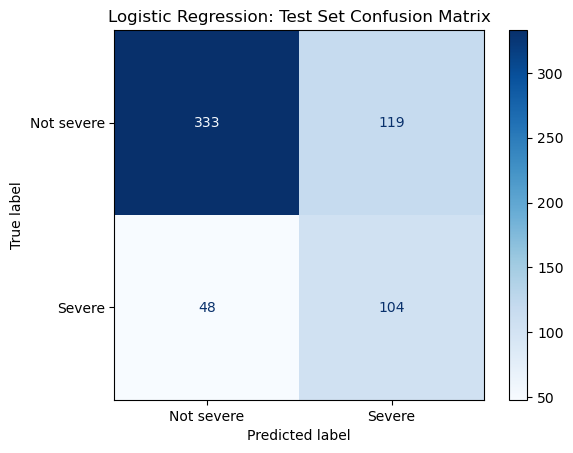

In [73]:
#confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(y_test, y_pred)
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=["Not severe", "Severe"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Logistic Regression: Test Set Confusion Matrix")
plt.savefig("../figures/10_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

Of the 152 severe hospitals in the test set, the model correctly identified 104  and
missed 48. It flagged 223 hospitals as severe, and 104 of them truly were ; the other
119 were false alarms.

For a screening tool, this trade-off is reasonable: missing a severe hospital is more
costly than reviewing one that turns out to be fine, so catching most severe hospitals
matters more than avoiding every false alarm.

## Summary

### Model performance
| Model | Recall | Precision | AUC |
|---|---|---|---|
| Baseline (always "not severe") | 0.00 | — | 0.50 |
| Logistic regression, cross-validation | 0.69 | 0.46 | 0.78 |
| Logistic regression, test set | 0.68 | 0.47 | 0.80 |
| Logistic regression without regular ED time (cross-validation) | 0.70 | 0.36 | 0.69 |

The model finds about two-thirds of the hospitals with the longest mental health ED stays,
far better than the baseline. Test results match cross-validation, so the model is not
overfitting.

### Key findings
1. **Overall ED flow is the strongest predictor.** Hospitals where regular ED patients stay
   longer have much higher odds of severe mental health ED stays: about 3 times the odds for
   each additional ~51 minutes of regular ED time (OR = 3.06, 95% CI 2.63–3.55).
2. **Hospital characteristics matter mainly through ED flow.** Without regular ED time,
   higher ER volume, the Northeast, and Acute Care hospitals are significantly linked to
   severe stays. Once regular ED time is included, none of them remain significant.
3. **Star rating and quality scores add little.** A hospital's overall star rating and its
   mortality, safety, and readmission scores were not significantly related to severe
   mental health ED stays.

### What this could mean for hospitals
- **Look at overall ED flow first.** Hospitals with slow EDs for all patients are the ones
  most likely to keep mental health patients the longest, so improving overall ED flow may
  also help mental health patients.
- **Don't rely on overall ratings.** A good star rating does not indicate short mental
  health ED stays, so this measure should be tracked directly.
- **Screening:** using only public CMS data, the model can flag hospitals likely to have
  severe mental health ED stays, to help decide where to look more closely.

### Limitations
- **Association, not cause:** the model shows which characteristics are linked to long
  stays, not what causes them.
- **Only hospitals that report the measure are included.** 1,635 hospitals were missing it,
  most because they had too few mental health ED cases, so small and rural hospitals are
  underrepresented. Model performance was not checked separately for rural hospitals.
- **OP-18c measures ED length of stay for patients discharged from the ED,** not boarding
  time for admitted patients.
- **One time period** of CMS data.
- **No direct capacity data,** such as the number of psychiatric beds available.

### Next steps
- Add other ED crowding measures, such as the share of patients who leave without being seen (OP-22)
- **Only hospitals that report the measure are included.** 1,635 hospitals were missing it,
  most because they had too few mental health ED cases, so small and rural hospitals are
  underrepresented. The model cannot be evaluated for hospitals that don't report, and its
  performance was not checked separately for the Critical Access hospitals that do report.
- Adjust for hospitals that don't report (e.g., inverse probability weighting)
- Add psychiatric bed capacity data and multiple years of CMS data
- Try a more flexible model, such as gradient boosting, to check for patterns logistic
  regression may miss